# Pipeline de OCR passo a passo

Este notebook executa, etapa por etapa, as mesmas funções usadas por `main.py`
(`scripts/preprocessamento.py`, `scripts/ocr.py` e `scripts/avaliacao.py`), mostrando
o resultado intermediário de cada uma:

1. Localização dos documentos e páginas
2. Pré-processamento (cada transformação e cada perfil)
3. PaddleOCR: resultado bruto (detecção + reconhecimento)
4. Reconstrução da ordem de leitura
5. Texto final e sinalização para revisão humana
6. Gravação dos resultados (TXT/JSON) como no `main.py`
7. Avaliação: relatório, comparativo de perfis, CER/WER e elementos jurídicos
8. Metadados jurídicos: norma, estrutura, artigos, citações e pendências (`metadados.json`)

Nenhuma etapa corrige o texto reconhecido: o que aparece é a saída bruta do modelo.

**Como abrir:** na pasta do projeto, execute
`.venv/bin/jupyter lab pipeline_passo_a_passo.ipynb` e use o kernel do `.venv`.

## 0. Configuração

In [1]:
import os
import sys
import json
import time
from pathlib import Path

# O notebook fica na raiz do projeto; todos os caminhos são relativos a ela.
RAIZ = Path.cwd()
if not (RAIZ / "scripts").is_dir():
    raise RuntimeError("Abra o notebook a partir da pasta Projeto_OCR_Leis.")
sys.path.insert(0, str(RAIZ))
os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scripts import preprocessamento as pre
from scripts import ocr
from scripts import avaliacao

PASTA_IMAGENS = RAIZ / "imagens"
PASTA_RESULTADOS = RAIZ / "resultados"
PASTA_REFERENCIAS = RAIZ / "referencias"


def mostrar(imagem, titulo="", ax=None, largura=10):
    """Exibe uma imagem BGR ou em escala de cinza."""
    if ax is None:
        altura = largura * imagem.shape[0] / imagem.shape[1]
        _, ax = plt.subplots(figsize=(largura, altura))
    if imagem.ndim == 2:
        ax.imshow(imagem, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB))
    ax.set_title(titulo)
    ax.axis("off")
    return ax

### Parâmetros do experimento

Altere aqui o documento, a página e o perfil de pré-processamento a analisar.

In [2]:
DOCUMENTO = "02_estatuto_idoso"
NUMERO_PAGINA = 3          # 1, 2, 3...
PERFIL = "original"        # veja a lista de perfis na etapa 2
LIMIAR_CONFIANCA = 0.80    # abaixo disto o trecho vai para revisão humana
DETECTAR_COLUNAS = True

## 1. Localização dos documentos e páginas

`ocr.listar_paginas()` percorre `imagens/<documento>/imagens_do_documento/`, ordena os arquivos
pela ordenação natural do nome e expande PDFs em uma página por folha.

In [3]:
for pasta_doc in sorted(p for p in PASTA_IMAGENS.iterdir() if p.is_dir()):
    paginas = ocr.listar_paginas(pasta_doc)
    print(f"{pasta_doc.name}: {len(paginas)} página(s)")
    for p in paginas:
        print(f"   {p.numero:>3}  {p.origem}")

01_exposicao_motivos_1983: 0 página(s)
02_estatuto_idoso: 3 página(s)
     1  pagina_001_estatuto-do-idoso-exemplar.jpg
     2  pagina_002_estatuto-do-idoso-interna-antes.jpg
     3  pagina_003_estatuto-do-idoso-pagina-interna.jpg


Página 3: pagina_003_estatuto-do-idoso-pagina-interna.jpg — 385x542 px


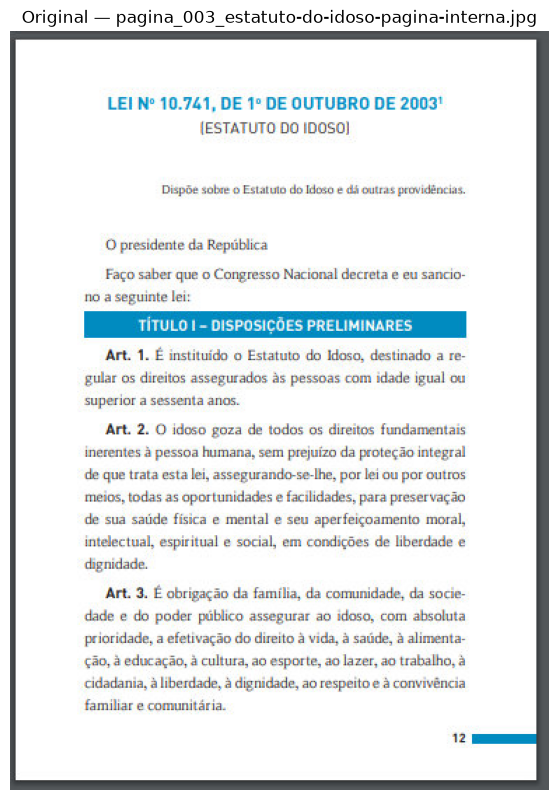

In [4]:
paginas = ocr.listar_paginas(PASTA_IMAGENS / DOCUMENTO)
if not paginas:
    raise RuntimeError(f"Nenhuma imagem em imagens/{DOCUMENTO}/imagens_do_documento/")
pagina = paginas[NUMERO_PAGINA - 1]
imagem_original = pagina.carregar()
print(f"Página {pagina.numero}: {pagina.origem} — {imagem_original.shape[1]}x{imagem_original.shape[0]} px")
mostrar(imagem_original, f"Original — {pagina.origem}", largura=7);

## 2. Pré-processamento

### 2.1 Cada transformação isolada

Todas as funções estão em `scripts/preprocessamento.py` e podem ser combinadas livremente.

Redimensionamento: 385 px -> 1600 px de largura
Inclinação estimada: +0.00° (correção aplicada somente se |ângulo| >= 0,3°)


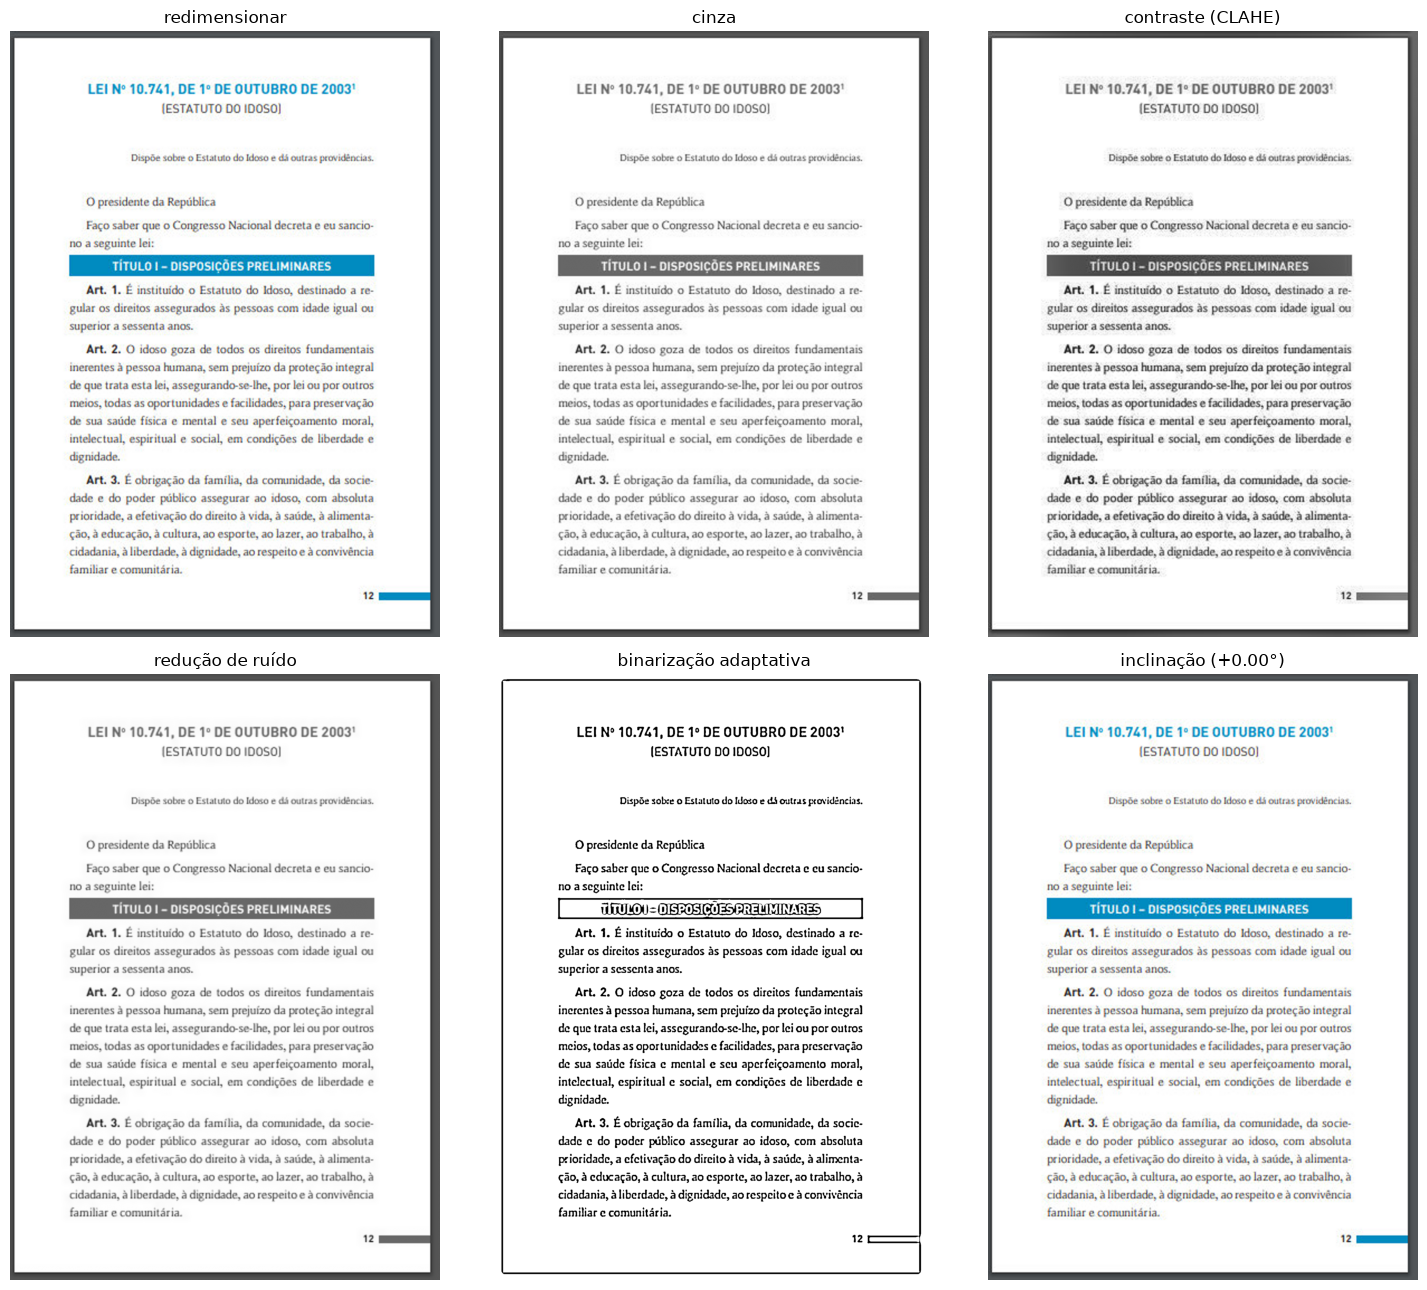

In [5]:
ampliada = pre.redimensionar(imagem_original)
cinza = pre.escala_cinza(ampliada)
contraste = pre.aumentar_contraste(cinza)
sem_ruido = pre.reduzir_ruido(cinza)
binarizada = pre.binarizacao_adaptativa(sem_ruido)
angulo = pre.estimar_inclinacao(ampliada)
endireitada = pre.corrigir_inclinacao(ampliada)

print(f"Redimensionamento: {imagem_original.shape[1]} px -> {ampliada.shape[1]} px de largura")
print(f"Inclinação estimada: {angulo:+.2f}° (correção aplicada somente se |ângulo| >= 0,3°)")

etapas = [
    ("redimensionar", ampliada), ("cinza", cinza), ("contraste (CLAHE)", contraste),
    ("redução de ruído", sem_ruido), ("binarização adaptativa", binarizada),
    (f"inclinação ({angulo:+.2f}°)", endireitada),
]
fig, eixos = plt.subplots(2, 3, figsize=(15, 13))
for ax, (nome, img) in zip(eixos.ravel(), etapas):
    mostrar(img, nome, ax=ax)
plt.tight_layout()

### 2.2 Detalhe ampliado

A binarização e a redução de ruído podem apagar detalhes finos (acentos, `º`, `§`).
Compare o mesmo recorte em cada versão.

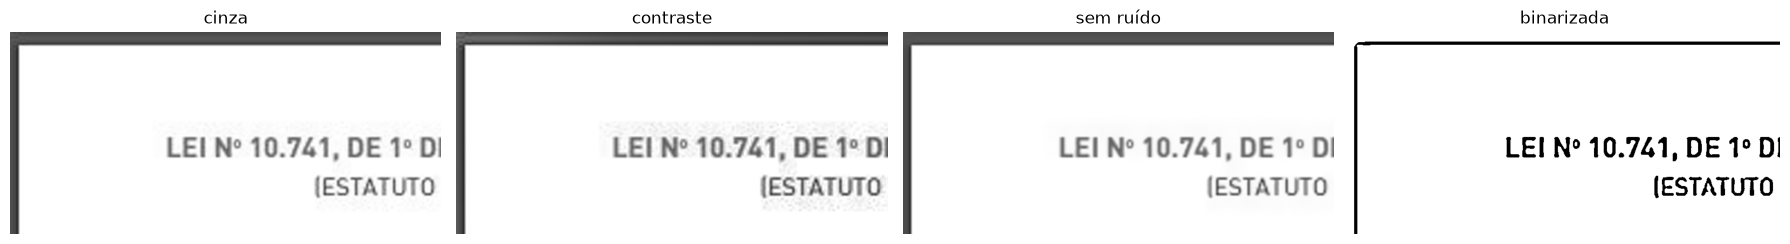

In [6]:
h, w = cinza.shape
recorte = (slice(0, h // 6), slice(0, w // 2))   # canto superior esquerdo (título da lei)
fig, eixos = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nome, img) in zip(eixos, [("cinza", cinza), ("contraste", contraste),
                                    ("sem ruído", sem_ruido), ("binarizada", binarizada)]):
    mostrar(img[recorte], nome, ax=ax)
plt.tight_layout()

### 2.3 Perfis usados nos testes comparativos

Um perfil é uma sequência de etapas (`pre.PERFIS`). `pre.aplicar_perfil()` sempre devolve
uma imagem BGR de 3 canais, o formato esperado pelo PaddleOCR.

original         (sem alteração)
ampliado         redimensionar
cinza_contraste  redimensionar -> cinza -> contraste
sem_ruido        redimensionar -> cinza -> ruido
binarizado       redimensionar -> cinza -> ruido -> binarizar
deskew           redimensionar -> inclinacao
completo         redimensionar -> cinza -> contraste -> ruido -> inclinacao -> binarizar


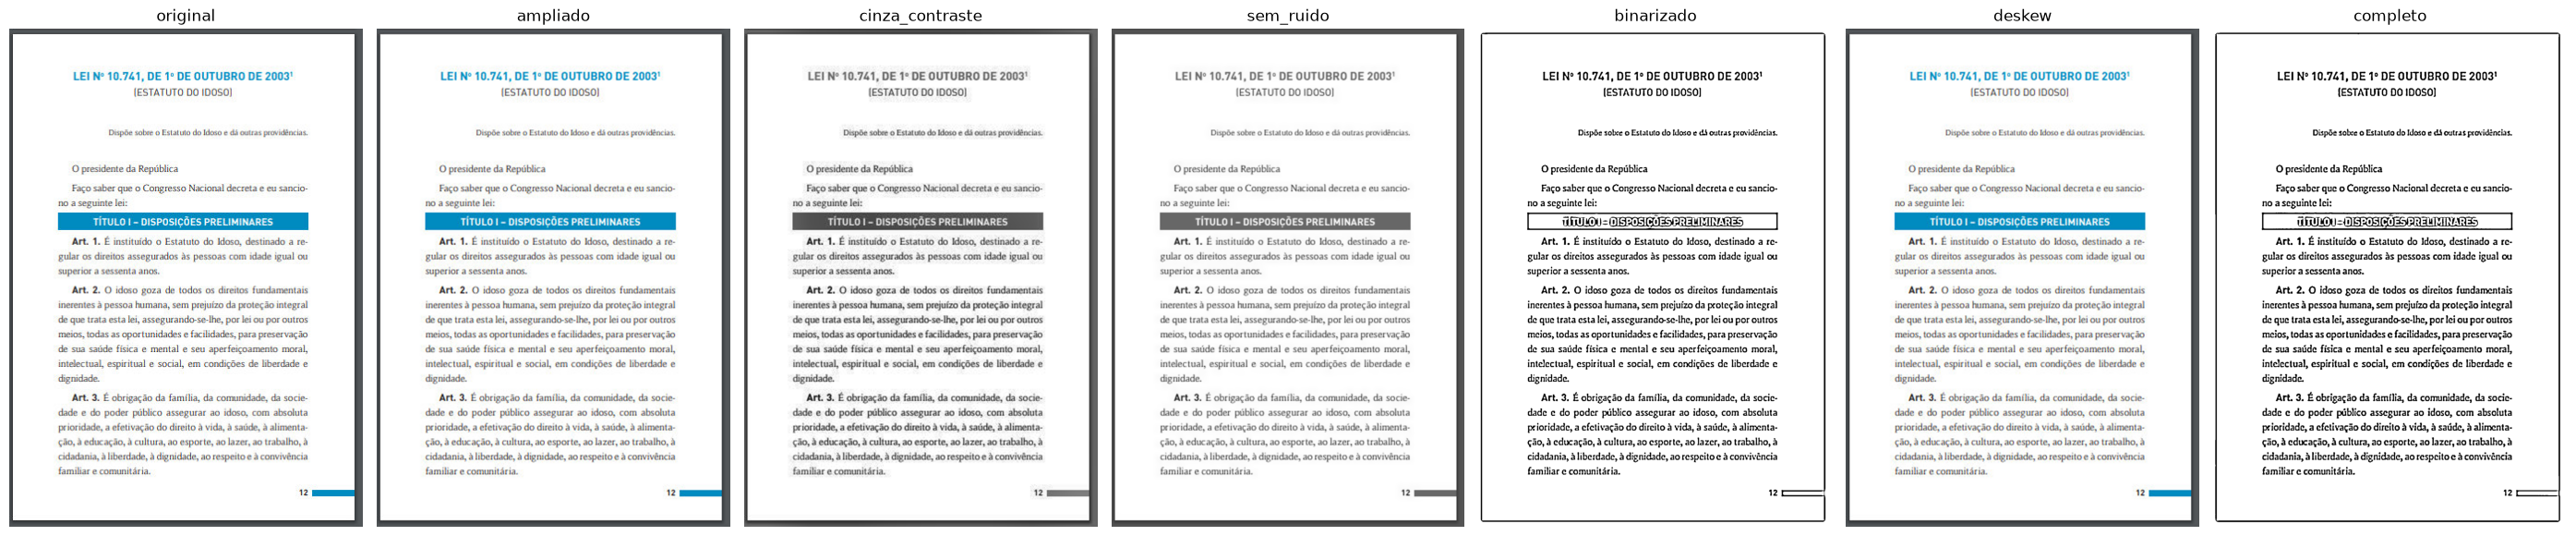

In [7]:
for nome, etapas_perfil in pre.PERFIS.items():
    print(f"{nome:16s} {' -> '.join(etapas_perfil) or '(sem alteração)'}")

fig, eixos = plt.subplots(1, len(pre.PERFIS), figsize=(4 * len(pre.PERFIS), 6))
for ax, nome in zip(eixos, pre.PERFIS):
    mostrar(pre.aplicar_perfil(imagem_original, nome), nome, ax=ax)
plt.tight_layout()

In [8]:
inicio = time.perf_counter()
imagem_entrada = pre.aplicar_perfil(imagem_original, PERFIL)
print(f"Perfil '{PERFIL}': {time.perf_counter() - inicio:.3f}s — imagem entregue ao OCR: "
      f"{imagem_entrada.shape[1]}x{imagem_entrada.shape[0]} px")

Perfil 'original': 0.000s — imagem entregue ao OCR: 385x542 px


## 3. PaddleOCR — resultado bruto

`ocr.MotorOCR` carrega o pipeline do PaddleOCR 3.x uma única vez (`lang="pt"`, CPU).
O primeiro carregamento leva alguns segundos; a primeira execução da vida do projeto
baixa os modelos para `~/.paddlex/`.

In [9]:
inicio = time.perf_counter()
motor = ocr.MotorOCR(idioma="pt", dispositivo="cpu")
print(f"Modelos carregados em {time.perf_counter() - inicio:.1f}s")
print("Versões:", motor.versoes())
print("Parâmetros:", motor.parametros)

Modelos carregados em 1.6s
Versões: {'paddleocr': '3.4.1', 'paddlepaddle': '3.2.2'}
Parâmetros: {'lang': 'pt', 'device': 'cpu', 'use_doc_orientation_classify': False, 'use_doc_unwarping': False, 'use_textline_orientation': False}


In [10]:
inicio = time.perf_counter()
bruto = motor.reconhecer(imagem_entrada)
tempo_ocr = time.perf_counter() - inicio

print(f"Tempo de OCR: {tempo_ocr:.2f}s")
print("Chaves do resultado bruto:", list(bruto.keys()))
print(f"Trechos detectados: {len(bruto.get('rec_texts', []))}")
print()
print("Primeiros trechos, NA ORDEM DEVOLVIDA PELO MODELO (texto | confiança | caixa x1,y1,x2,y2):")
for i, (t, s, b) in enumerate(zip(bruto["rec_texts"], bruto["rec_scores"], bruto["rec_boxes"])):
    if i == 15:
        break
    print(f"  {i:>3}  {s:.3f}  {list(map(int, b))}  {t}")

Tempo de OCR: 1.05s
Chaves do resultado bruto: ['input_path', 'page_index', 'model_settings', 'dt_polys', 'text_det_params', 'text_type', 'textline_orientation_angles', 'text_rec_score_thresh', 'return_word_box', 'rec_texts', 'rec_scores', 'rec_polys', 'rec_boxes']
Trechos detectados: 24

Primeiros trechos, NA ORDEM DEVOLVIDA PELO MODELO (texto | confiança | caixa x1,y1,x2,y2):
    0  0.962  [68, 44, 309, 57]  LEI N° 10.741, DE 1º DE 0UTUBRO DE 2003
    1  0.945  [133, 60, 243, 74]  (ESTATUTO DO IDOSO)
    2  0.984  [106, 106, 327, 119]  Dispõe sobre o Estatuto do Idoso e dá outras providências.
    3  0.999  [64, 144, 184, 158]  O presidente da República
    4  0.993  [65, 166, 326, 179]  Faço saber que o Congresso Nacional decreta e eu sancio-
    5  0.996  [50, 182, 131, 195]  no a seguinte lei:
    6  0.972  [90, 202, 288, 215]  TÍTULO I - DISPOSICÕES PRELIMINARES
    7  0.975  [64, 222, 326, 237]  Art. 1. É instituído o Estatuto do Idoso, destinado a re-
    8  0.983  [51, 240, 32

### 3.1 Detecção sobre a imagem

Cada caixa é um trecho reconhecido. Cores: **verde** = confiança ≥ limiar,
**vermelho** = abaixo do limiar (vai para revisão humana).

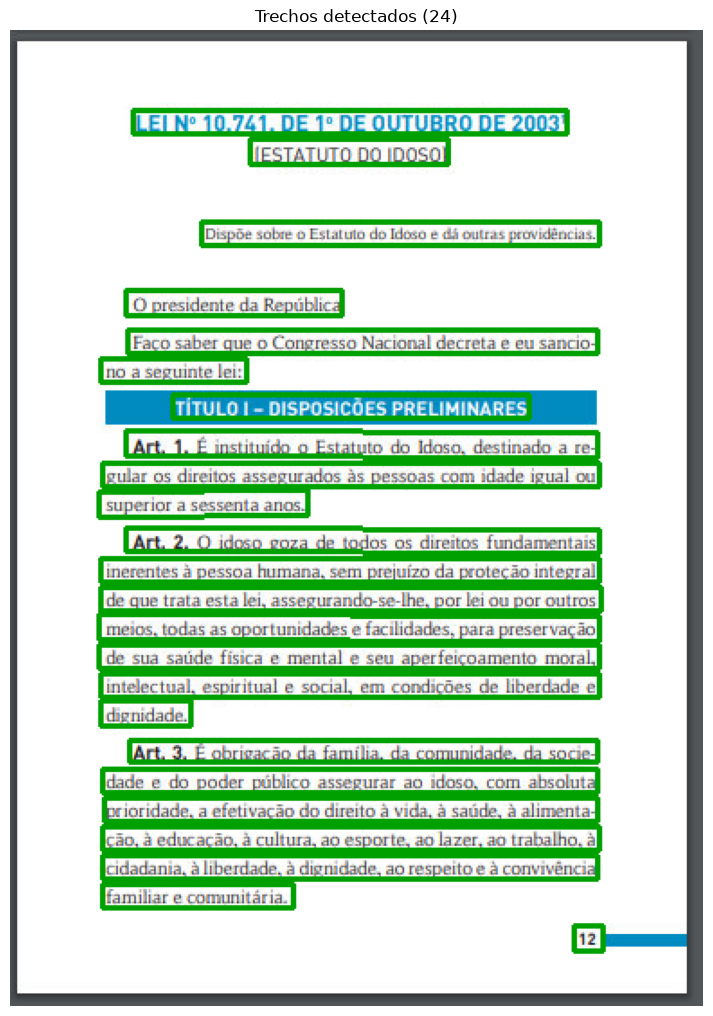

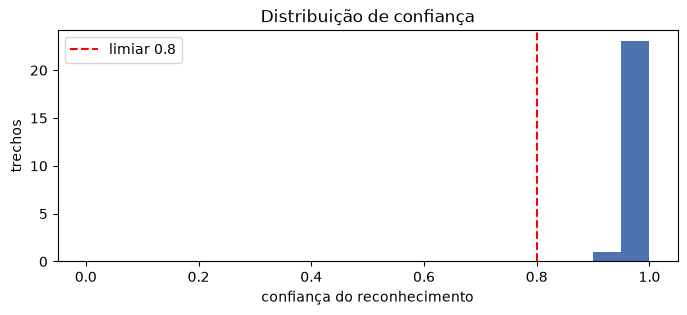

In [11]:
desenho = imagem_entrada.copy()
for poligono, score in zip(bruto["rec_polys"], bruto["rec_scores"]):
    cor = (0, 160, 0) if score >= LIMIAR_CONFIANCA else (0, 0, 230)
    cv2.polylines(desenho, [np.array(poligono, dtype=np.int32)], True, cor, 2)
mostrar(desenho, f"Trechos detectados ({len(bruto['rec_texts'])})", largura=9);

plt.figure(figsize=(8, 3))
plt.hist(bruto["rec_scores"], bins=20, range=(0, 1), color="#4c72b0")
plt.axvline(LIMIAR_CONFIANCA, color="red", linestyle="--", label=f"limiar {LIMIAR_CONFIANCA}")
plt.xlabel("confiança do reconhecimento"); plt.ylabel("trechos"); plt.legend()
plt.title("Distribuição de confiança");

## 4. Ordem de leitura

O modelo não garante a ordem de leitura. `ocr.ordenar_leitura()` agrupa os trechos em linhas
visuais e, se encontrar um corredor vertical vazio, trata a página como duas colunas
(coluna esquerda inteira, depois a direita; títulos de largura total ficam na posição correta).

In [12]:
itens = [
    {"indice_paddleocr": i, "texto": t, "confianca": float(s), "caixa": [float(v) for v in b]}
    for i, (t, s, b) in enumerate(zip(bruto["rec_texts"], bruto["rec_scores"], bruto["rec_boxes"]))
]
linhas_visuais, layout = ocr.ordenar_leitura(itens, imagem_entrada.shape[1], DETECTAR_COLUNAS)
print("Layout detectado:", layout)
print(f"{len(itens)} trechos agrupados em {len(linhas_visuais)} linhas")

Layout detectado: {'colunas': 1}
24 trechos agrupados em 24 linhas


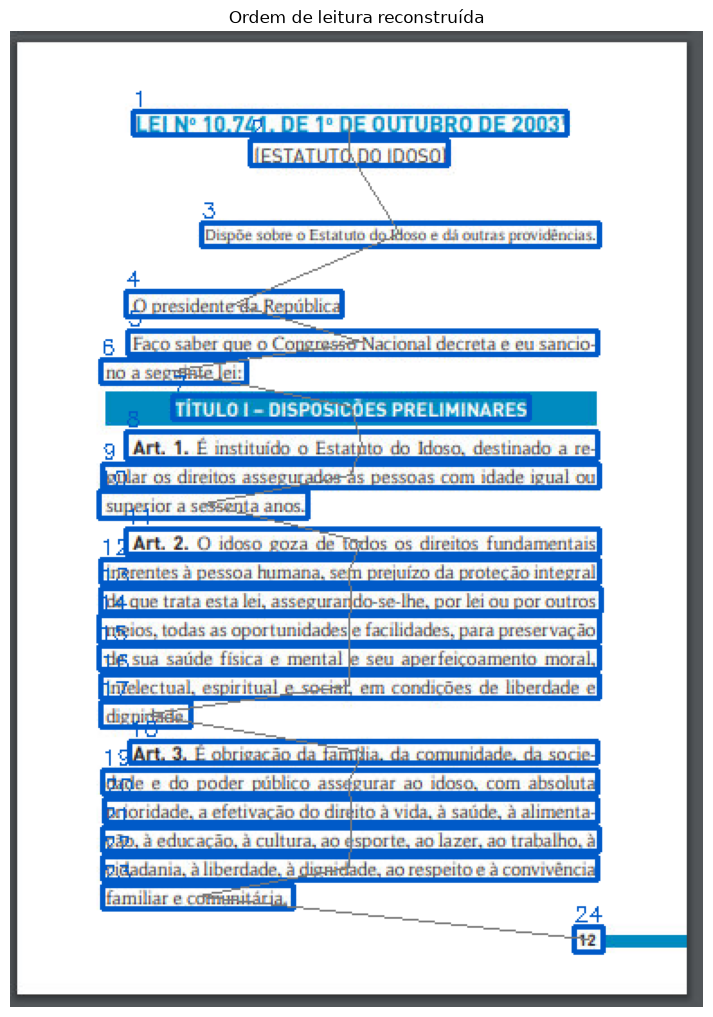

In [13]:
# Numera cada trecho na ordem de leitura final. Cor por coluna:
# azul = coluna 1, laranja = coluna 2, roxo = largura total.
cores = {0: (160, 0, 160), 1: (200, 90, 0), 2: (0, 120, 255)}
desenho = imagem_entrada.copy()
ordem = 0
centros = []
for linha in linhas_visuais:
    for item in linha:
        ordem += 1
        x1, y1, x2, y2 = map(int, item["caixa"])
        cv2.rectangle(desenho, (x1, y1), (x2, y2), cores[item["coluna"]], 2)
        cv2.putText(desenho, str(ordem), (x1, max(12, y1 - 3)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.4 * max(1, imagem_entrada.shape[1] / 800), cores[item["coluna"]], 1)
        centros.append(((x1 + x2) // 2, (y1 + y2) // 2))
for a, b in zip(centros, centros[1:]):
    cv2.line(desenho, a, b, (120, 120, 120), 1)
mostrar(desenho, "Ordem de leitura reconstruída", largura=9);

## 5. Texto final e revisão humana

Cada linha visual vira uma linha do TXT; trechos da mesma linha são unidos por espaço.
O texto de cada trecho é o bruto do modelo. A revisão humana é **apenas sinalizada**:
- confiança abaixo do limiar;
- mistura suspeita de letras e dígitos (O/0, l/1, S/5);
- símbolo de grau `°` onde se espera o ordinal `º`.

In [14]:
texto = "\n".join(" ".join(item["texto"] for item in linha) for linha in linhas_visuais)
print(texto)

LEI N° 10.741, DE 1º DE 0UTUBRO DE 2003
(ESTATUTO DO IDOSO)
Dispõe sobre o Estatuto do Idoso e dá outras providências.
O presidente da República
Faço saber que o Congresso Nacional decreta e eu sancio-
no a seguinte lei:
TÍTULO I - DISPOSICÕES PRELIMINARES
Art. 1. É instituído o Estatuto do Idoso, destinado a re-
gular os direitos assegurados às pessoas com idade igual ou
superior a sessenta anos.
Art. 2. O idoso goza de todos os direitos fundamentais
inerentes à pessoa humana, sem prejuízo da proteção integral
de que trata esta lei, assegurando-se-lhe, por lei ou por outros
meios, todas as oportunidades e facilidades, para preservação
de sua saúde física e mental e seu aperfeiçoamento moral,
intelectual, espiritual e social, em condições de liberdade e
dignidade.
Art. 3. É obrigação da família, da comunidade, da socie-
dade e do poder público assegurar ao idoso, com absoluta
prioridade, a efetivação do direito à vida, à saúde, à alimenta-
ção, à educação, à cultura, ao esporte, ao laz

In [15]:
revisao = []
for n_linha, linha in enumerate(linhas_visuais, start=1):
    for item in linha:
        motivos = []
        if item["confianca"] < LIMIAR_CONFIANCA:
            motivos.append(f"confiança {item['confianca']:.3f} < {LIMIAR_CONFIANCA}")
        motivos += ocr.sinais_de_ambiguidade(item["texto"])
        if motivos:
            revisao.append((n_linha, item["texto"], motivos))

print(f"{len(revisao)} trecho(s) para revisão humana:\n")
for n_linha, trecho, motivos in revisao:
    print(f"linha {n_linha:>3}: {trecho!r}")
    for m in motivos:
        print(f"           - {m}")

1 trecho(s) para revisão humana:

linha   1: 'LEI N° 10.741, DE 1º DE 0UTUBRO DE 2003'
           - mistura de letras e dígitos em '0UTUBRO' (ex.: O/0, l/1, S/5)
           - símbolo de grau '°' em possível posição de ordinal 'º' (Art. 1º, nº, § 1º)


### 5.1 Elementos jurídicos encontrados no texto reconhecido

`avaliacao.extrair_elementos_juridicos()` lista artigos, parágrafos, incisos, alíneas,
leis e datas **exatamente como o OCR os escreveu** — útil para conferir rapidamente
símbolos como `º`/`°`.

In [16]:
for categoria, itens_encontrados in avaliacao.extrair_elementos_juridicos(texto).items():
    print(f"{categoria:11s} ({len(itens_encontrados)}): {itens_encontrados}")

artigos     (3): ['Art. 1', 'Art. 2', 'Art. 3']
paragrafos  (0): []
incisos     (0): []
alineas     (0): []
leis        (1): ['LEI N° 10.741']
datas       (0): []


## 6. Gravação dos resultados (igual ao `main.py`)

`ocr.processar_documento()` executa as etapas 2 a 5 para todas as páginas do documento e grava
`pagina_NNN.txt`, `pagina_NNN.json` e `documento_completo.txt`. O perfil `original` grava em
`resultados/<documento>/`; os demais, em `resultados/<documento>/preprocessado_<perfil>/`.
Resultados anteriores do mesmo perfil são substituídos.

In [17]:
for reg in ocr.processar_documento(
    motor, PASTA_IMAGENS / DOCUMENTO, PASTA_RESULTADOS, PERFIL, LIMIAR_CONFIANCA,
    detectar_colunas=DETECTAR_COLUNAS,
):
    if reg["status"] == "ok":
        print(f"página {reg['pagina']}: {reg['quantidade_palavras']} palavras, "
              f"{reg['tempo_ocr_s']:.2f}s, {reg['layout']['colunas']} coluna(s), "
              f"{len(reg['revisao_humana'])} trecho(s) p/ revisão")
    else:
        print(f"página {reg['pagina']}: ERRO — {reg['erro']}")

pasta_saida = ocr.pasta_saida_para(PASTA_RESULTADOS / DOCUMENTO, PERFIL)
print("\nArquivos em", pasta_saida.relative_to(RAIZ))
for arq in sorted(pasta_saida.iterdir()):
    if arq.is_file():
        print(f"   {arq.name:28s} {arq.stat().st_size:>8} bytes")

página 1: 4 palavras, 0.56s, 1 coluna(s), 1 trecho(s) p/ revisão


página 2: 705 palavras, 4.58s, 2 coluna(s), 17 trecho(s) p/ revisão


página 3: 185 palavras, 1.10s, 1 coluna(s), 1 trecho(s) p/ revisão

Arquivos em resultados/02_estatuto_idoso
   comparativo_perfis.json          2470 bytes
   comparativo_perfis.md             822 bytes
   documento_completo.txt           5942 bytes
   metadados.json                  30677 bytes
   pagina_001.json                  3378 bytes
   pagina_001.txt                     21 bytes
   pagina_002.json                 96315 bytes
   pagina_002.txt                   4547 bytes
   pagina_003.json                 24085 bytes
   pagina_003.txt                   1157 bytes
   relatorio.json                   1801 bytes
   relatorio.md                      680 bytes


In [18]:
registro = json.loads((pasta_saida / f"{ocr.nome_pagina(NUMERO_PAGINA)}.json").read_text(encoding="utf-8"))
resumo = {k: v for k, v in registro.items()
          if k not in ("texto", "linhas_ordenadas", "resultado_bruto_paddleocr", "revisao_humana")}
print(json.dumps(resumo, ensure_ascii=False, indent=2))

{
  "documento": "02_estatuto_idoso",
  "pagina": 3,
  "imagem_origem": "pagina_003_estatuto-do-idoso-pagina-interna.jpg",
  "perfil_preprocessamento": "original",
  "etapas_preprocessamento": [],
  "limiar_confianca_revisao": 0.8,
  "parametros_paddleocr": {
    "lang": "pt",
    "device": "cpu",
    "use_doc_orientation_classify": false,
    "use_doc_unwarping": false,
    "use_textline_orientation": false
  },
  "versoes": {
    "paddleocr": "3.4.1",
    "paddlepaddle": "3.2.2"
  },
  "tempo_preprocessamento_s": 0.0018,
  "dimensoes_imagem": {
    "largura": 385,
    "altura": 542
  },
  "tempo_ocr_s": 1.1031,
  "status": "ok",
  "layout": {
    "colunas": 1
  },
  "quantidade_caracteres": 1110,
  "quantidade_palavras": 185,
  "quantidade_fragmentos": 24,
  "confianca_media": 0.9867,
  "confianca_minima": 0.9454,
  "necessita_revisao_humana": true
}


## 7. Avaliação

### 7.1 Relatório do perfil

CER e WER só são calculados quando existe `referencias/<documento>/pagina_NNN.txt`
(transcrição revisada por humanos). Sem referência, aparecem como `—`: nada é estimado.

In [19]:
relatorio = avaliacao.gerar_relatorio(pasta_saida, PASTA_REFERENCIAS / DOCUMENTO)
display(Markdown(avaliacao.tabela_markdown(relatorio["paginas"], relatorio["resumo"])))

| Documento | Imagem | Perfil | Caracteres | Palavras | Tempo OCR (s) | CER | WER | Revisão |
|---|---|---|---:|---:|---:|---:|---:|---:|
| 02_estatuto_idoso | pagina_001_estatuto-do-idoso-exemplar.jpg | original | 20 | 4 | 0.56 | — | — | 1 |
| 02_estatuto_idoso | pagina_002_estatuto-do-idoso-interna-antes.jpg | original | 4336 | 705 | 4.58 | — | — | 17 |
| 02_estatuto_idoso | pagina_003_estatuto-do-idoso-pagina-interna.jpg | original | 1110 | 185 | 1.10 | — | — | 1 |

Páginas: 3 · com erro: 0 · avaliadas (com referência): 0 · CER médio: — · WER médio: —

CER/WER = — : nenhuma transcrição de referência disponível; métricas não calculadas.


### 7.2 Comparativo entre perfis

Disponível depois de executar mais de um perfil (por exemplo `python main.py --comparar`).

| Perfil | Etapas | Páginas avaliadas | CER médio | WER médio | Confiança média | Trechos p/ revisão | Caracteres | Tempo OCR (s) |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| original | — | 0 | — | — | 0.9438 | 19 | 5466 | 6.639 |
| ampliado | redimensionar | 0 | — | — | 0.8844 | 16 | 5478 | 31.307 |
| binarizado | redimensionar, cinza, ruido, binarizar | 0 | — | — | 0.8689 | 14 | 5386 | 28.614 |
| cinza_contraste | redimensionar, cinza, contraste | 0 | — | — | 0.9009 | 18 | 5467 | 32.367 |
| completo | redimensionar, cinza, contraste, ruido, inclinacao, binarizar | 0 | — | — | 0.8742 | 15 | 5399 | 28.029 |
| deskew | redimensionar, inclinacao | 0 | — | — | 0.8909 | 16 | 5477 | 29.409 |
| sem_ruido | redimensionar, cinza, ruido | 0 | — | — | 0.9090 | 21 | 5443 | 32.594 |


Sem transcrições de referência: o comparativo de CER/WER ainda não pode ser feito.
A confiança média NÃO mede acerto; use-a apenas como indicativo.


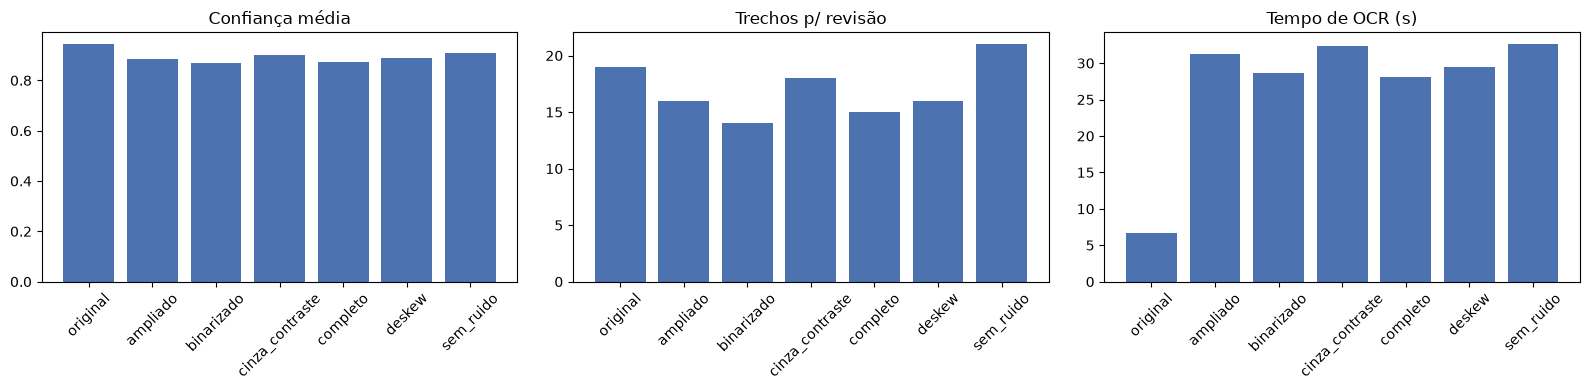

In [20]:
comparativo = PASTA_RESULTADOS / DOCUMENTO / "comparativo_perfis.json"
if comparativo.is_file():
    linhas = json.loads(comparativo.read_text(encoding="utf-8"))
    display(Markdown((PASTA_RESULTADOS / DOCUMENTO / "comparativo_perfis.md").read_text(encoding="utf-8")))

    nomes = [l["perfil"] for l in linhas]
    fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
    for ax, chave, titulo in zip(eixos, ["confianca_media", "trechos_para_revisao", "tempo_ocr_total_s"],
                                 ["Confiança média", "Trechos p/ revisão", "Tempo de OCR (s)"]):
        ax.bar(nomes, [l[chave] or 0 for l in linhas], color="#4c72b0")
        ax.set_title(titulo); ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    if any(l["cer_medio"] is not None for l in linhas):
        plt.figure(figsize=(8, 3))
        plt.bar(nomes, [l["cer_medio"] or 0 for l in linhas], color="#c44e52")
        plt.title("CER médio (menor é melhor)"); plt.xticks(rotation=45)
    else:
        print("Sem transcrições de referência: o comparativo de CER/WER ainda não pode ser feito.")
        print("A confiança média NÃO mede acerto; use-a apenas como indicativo.")
else:
    print("Comparativo ainda não gerado. Execute: .venv/bin/python main.py --comparar")

### 7.3 Como o CER e o WER são calculados

Exemplo **didático** com frases curtas escritas para ilustrar a métrica (não é resultado
de nenhum documento): uma troca de `º` por `°` e de `O` por `0`.

In [21]:
referencia_exemplo = "Art. 1º É instituído o Estatuto, de 1º de outubro."
hipotese_exemplo = "Art. 1° É instituído o Estatuto, de 1º de 0utubro."
print("CER:", round(avaliacao.calcular_cer(referencia_exemplo, hipotese_exemplo), 4),
      "(2 caracteres errados /", len(referencia_exemplo), "caracteres)")
print("WER:", round(avaliacao.calcular_wer(referencia_exemplo, hipotese_exemplo), 4),
      "(2 palavras erradas /", len(referencia_exemplo.split()), "palavras)")
print(json.dumps(avaliacao.comparar_elementos_juridicos(referencia_exemplo, hipotese_exemplo)["artigos"],
                 ensure_ascii=False, indent=2))

CER: 0.04 (2 caracteres errados / 50 caracteres)
WER: 0.2 (2 palavras erradas / 10 palavras)
{
  "na_referencia": 1,
  "preservados_no_ocr": 0,
  "taxa_preservacao": 0.0,
  "ausentes_ou_divergentes": [
    "Art. 1º"
  ]
}


### 7.4 Avaliando o documento real

1. Transcreva (ou revise) a página manualmente e salve em
   `referencias/<documento>/pagina_NNN.txt` (mesma numeração dos resultados).
2. Rode a célula abaixo (ou `.venv/bin/python main.py --somente-avaliacao`).

In [22]:
arq_ref = PASTA_REFERENCIAS / DOCUMENTO / f"{ocr.nome_pagina(NUMERO_PAGINA)}.txt"
if arq_ref.is_file() and arq_ref.read_text(encoding="utf-8").strip():
    resultado = avaliacao.avaliar_texto(arq_ref.read_text(encoding="utf-8"), registro.get("texto", ""))
    print(f"CER: {resultado['cer']}   WER: {resultado['wer']}")
    for categoria, dados in resultado["elementos_juridicos"].items():
        if dados["na_referencia"]:
            print(f"{categoria:11s} preservados {dados['preservados_no_ocr']}/{dados['na_referencia']}"
                  f"  divergentes: {dados['ausentes_ou_divergentes']}")
else:
    print(f"Sem referência em {arq_ref.relative_to(RAIZ)} — CER/WER não calculados.")

Sem referência em referencias/02_estatuto_idoso/pagina_003.txt — CER/WER não calculados.


## 8. Metadados jurídicos

`scripts/metadados.py` lê os `pagina_NNN.json` do perfil escolhido e transforma o texto
reconhecido em um JSON estruturado (`metadados.json`, gravado na mesma pasta dos resultados):

- **norma**: tipo, número, data, apelido e ementa (todas as ocorrências encontradas, com as
  divergências entre elas);
- **estrutura**: títulos, capítulos e seções;
- **artigos**, com a hierarquia **caput → parágrafos → incisos → alíneas** e a localização
  (título/capítulo) de cada artigo;
- **leis e datas citadas**, notas de rodapé e número de página impresso;
- **pendências**: problemas que impedem uma normalização segura ou fogem da técnica legislativa;
- **rastreabilidade**: página, linha, imagem de origem, confiança, perfil e versões.

Todo texto continua **bruto**. Os campos `*_normalizado` (ex.: data ISO) só são preenchidos
quando o texto bruto é inequívoco; caso contrário ficam `null` e o motivo vai para `pendencias`.
A classificação das linhas usa padrões de texto (regex) e depende de a ordem de leitura estar correta.

In [23]:
from scripts import metadados

metadados_doc, arquivo_metadados = metadados.salvar_metadados(pasta_saida)
print("Gravado em", arquivo_metadados.relative_to(RAIZ))
print(json.dumps(metadados_doc["estatisticas"], ensure_ascii=False, indent=2))

Gravado em resultados/02_estatuto_idoso/metadados.json
{
  "artigos": 13,
  "paragrafos": 4,
  "incisos": 15,
  "divisoes": 5,
  "artigos_com_revisao_humana": 10,
  "pendencias": 20
}


### 8.1 Identificação da norma

In [24]:
norma = metadados_doc["norma"]
tabela = ("| Pág. | Tipo | Número (bruto) | Número normalizado | Data (bruta) | Data normalizada | Pendências |\n"
          "|---:|---|---|---|---|---|---|\n")
for i in norma["identificacoes"]:
    tabela += (f"| {i['pagina']} | {i['tipo_bruto']} | {i['numero_bruto']} | {i['numero_normalizado'] or '—'} | "
               f"{i['data_bruta']} | {i['data_normalizada'] or '—'} | {'; '.join(i['pendencias']) or '—'} |\n")
display(Markdown(tabela))

print("Apelidos:", [a["texto_bruto"] for a in norma["apelidos"]])
for e in norma["ementas"]:
    print(f"Ementa (pág. {e['pagina']}):", e["texto_bruto"].replace("\n", " ⏎ "))
if norma["divergencias_entre_ocorrencias"]:
    print("\nDivergências entre as ocorrências do cabeçalho:")
    for campo, valores in norma["divergencias_entre_ocorrencias"].items():
        print(f"   {campo}: {valores}")

| Pág. | Tipo | Número (bruto) | Número normalizado | Data (bruta) | Data normalizada | Pendências |
|---:|---|---|---|---|---|---|
| 2 | LEI | 10.741 | 10741 | 1° DE OUTUBRO DE 2003 | 2003-10-01 | — |
| 3 | LEI | 10.741 | 10741 | 1º DE 0UTUBRO DE 2003 | — | mês '0UTUBRO' não é um nome de mês válido (possível erro de OCR) |


Apelidos: ['Estatuto do Idoso', 'ESTATUTO DO IDOSO']
Ementa (pág. 2): Dispõe sobre o Estatuto do Idoso e dá outras ⏎ providências.
Ementa (pág. 3): Dispõe sobre o Estatuto do Idoso e dá outras providências.

Divergências entre as ocorrências do cabeçalho:
   data_bruta: ['1° DE OUTUBRO DE 2003', '1º DE 0UTUBRO DE 2003']


### 8.2 Estrutura e dispositivos

Árvore reconstruída. `⚠` indica um dispositivo com trecho marcado para revisão humana
ou com pendência.

In [25]:
def marca(d):
    return " ⚠" if d.get("revisao_humana") or d.get("pendencias") else ""

def resumo_texto(d, n=70):
    t = d.get("texto_bruto", "").replace("\n", " ")
    return t if len(t) <= n else t[:n] + "…"

def imprimir_filhos(d, nivel):
    for chave in ("paragrafos", "incisos", "alineas"):
        for f in d.get(chave, []):
            rotulo = "§ " + f["rotulo_bruto"] if f["tipo"] == "paragrafo" and not f.get("unico") else f["rotulo_bruto"]
            print("    " * nivel + f"{rotulo}{marca(f)}  {resumo_texto(f)}")
            imprimir_filhos(f, nivel + 1)

localizacao_anterior = None
for artigo in metadados_doc["artigos"]:
    loc = tuple(artigo["localizacao"].values())
    if loc != localizacao_anterior:
        print("\n" + "\n".join(loc) if loc else "")
        localizacao_anterior = loc
    print(f"  [pág. {artigo['pagina']}] Art. {artigo['rotulo_bruto']}{marca(artigo)}  {resumo_texto(artigo)}")
    imprimir_filhos(artigo, 2)


TÍTULO I - DISPOSICÕES PRELIMINARES
  [pág. 2] Art. 1° ⚠  É instituído o Estatuto do Idoso, destinado a regular os direitos asse…
  [pág. 2] Art. 2° ⚠  O idoso goza de todos os direitos fundamentais inerentes à pessoa huma…
  [pág. 2] Art. 3° ⚠  É obrigação da familia, da comunidade, da so- ciedade e do poder públi…
        Parágrafoúnico  A garantia de prioridade compreende:
            I  atendimento preferencial imediato e individualizado junto aos órgãos p…
            Il ⚠  preferência naformulação e na execução de políticas sociais públicas e…
            III  destinação privilegiada de recursos públicos nas áreas relacionadas co…
            IV  viabilização de formas alternativas de participação, ocupação e convív…
            V  priorização do atendimento do idoso porsua própria família, em detrime…
            VI  capacitacão e reciclagem dos recursos humanos nas áreas de geriatria e…
            VIl ⚠  estabelecimento de mecanismos que favoreçam a divulqação de informaçõe…


### 8.3 Um artigo completo no JSON

In [26]:
# Primeiro artigo com parágrafos ou incisos (mostra a hierarquia); senão, o primeiro artigo.
exemplo = next((a for a in metadados_doc["artigos"] if a["paragrafos"] or a["incisos"]),
               metadados_doc["artigos"][0] if metadados_doc["artigos"] else None)
if exemplo:
    texto_json = json.dumps(exemplo, ensure_ascii=False, indent=2)
    print(texto_json if len(texto_json) < 6000 else texto_json[:6000] + "\n... (truncado)")
else:
    print("Nenhum artigo identificado nesta pasta de resultados.")

{
  "tipo": "artigo",
  "rotulo_bruto": "3°",
  "pagina": 2,
  "linha_inicio": 20,
  "pendencias": [
    "artigo '3°' usa o símbolo de grau '°' em vez do ordinal 'º'"
  ],
  "revisao_humana": [
    {
      "texto_bruto": "Art. 3° É obrigação da familia, da comunidade, da so-",
      "confianca": 0.9748818278312683,
      "motivos": [
        "símbolo de grau '°' em possível posição de ordinal 'º' (Art. 1º, nº, § 1º)"
      ]
    }
  ],
  "numero": 3,
  "localizacao": {
    "TITULO": "TÍTULO I - DISPOSICÕES PRELIMINARES"
  },
  "paragrafos": [
    {
      "tipo": "paragrafo",
      "rotulo_bruto": "Parágrafoúnico",
      "pagina": 2,
      "linha_inicio": 26,
      "pendencias": [],
      "revisao_humana": [],
      "unico": true,
      "numero": null,
      "incisos": [
        {
          "tipo": "inciso",
          "rotulo_bruto": "I",
          "pagina": 2,
          "linha_inicio": 27,
          "pendencias": [],
          "revisao_humana": [],
          "alineas": [],
          "t

### 8.4 Pendências

Itens que precisam de conferência humana antes de usar os metadados (nenhum foi corrigido).

In [27]:
if metadados_doc["pendencias"]:
    tabela = "| Onde | Motivo |\n|---|---|\n" + "".join(
        f"| {p['onde']} | {p['motivo']} |\n" for p in metadados_doc["pendencias"])
    display(Markdown(tabela))
else:
    print("Nenhuma pendência.")

| Onde | Motivo |
|---|---|
| LEI (pág. 3, linha 1) | mês '0UTUBRO' não é um nome de mês válido (possível erro de OCR) |
| Art. 1° (pág. 2, linha 10) | artigo '1°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 2° (pág. 2, linha 13) | artigo '2°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 3° (pág. 2, linha 20) | artigo '3°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 3° > paragrafo Parágrafoúnico > inciso Il (pág. 2, linha 30) | rótulo de inciso 'Il' não é algarismo romano válido (ex.: l/I, 1/I, marca de nota de rodapé) |
| Art. 3° > paragrafo Parágrafoúnico > inciso VIl (pág. 2, linha 43) | rótulo de inciso 'VIl' não é algarismo romano válido (ex.: l/I, 1/I, marca de nota de rodapé) |
| Art. 3° > paragrafo Parágrafoúnico > inciso VIll (pág. 2, linha 46) | rótulo de inciso 'VIll' não é algarismo romano válido (ex.: l/I, 1/I, marca de nota de rodapé) |
| Art. 3° > paragrafo Parágrafoúnico > inciso 2X (pág. 2, linha 49) | rótulo de inciso '2X' não é algarismo romano válido (ex.: l/I, 1/I, marca de nota de rodapé) |
| Art. 4° (pág. 2, linha 51) | artigo '4°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 4° > paragrafo 1° (pág. 2, linha 55) | parágrafo '1°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 4° > paragrafo 2° (pág. 2, linha 57) | parágrafo '2°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 5° (pág. 2, linha 60) | artigo '5°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 6° (pág. 2, linha 63) | artigo '6°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 7° (pág. 2, linha 67) | artigo '7°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 8° (pág. 2, linha 73) | artigo '8°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 9° (pág. 2, linha 76) | artigo '9°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 10 > paragrafo 1° (pág. 2, linha 87) | parágrafo '1°' usa o símbolo de grau '°' em vez do ordinal 'º' |
| Art. 1 (pág. 3, linha 8) | artigo '1' sem indicador ordinal 'º' (esperado para 1 a 9; possível perda no OCR) |
| Art. 2 (pág. 3, linha 11) | artigo '2' sem indicador ordinal 'º' (esperado para 1 a 9; possível perda no OCR) |
| Art. 3 (pág. 3, linha 18) | artigo '3' sem indicador ordinal 'º' (esperado para 1 a 9; possível perda no OCR) |


### 8.5 Citações, notas e textos não classificados

In [28]:
print("Leis citadas:")
for l in metadados_doc["leis_citadas"]:
    print(f"   pág. {l['pagina']}, linha {l['linha']}: {l['texto_bruto']}")
print("\nDatas citadas:")
for d in metadados_doc["datas_citadas"]:
    print(f"   pág. {d['pagina']}, linha {d['linha']}: {d['texto_bruto']}")
print("\nNotas de rodapé:")
for n in metadados_doc["notas_rodape"]:
    print(f"   pág. {n['pagina']}: {n['rotulo']}. {n['texto_bruto']}")
print("\nNúmero de página impresso:", [(p["pagina"], p["numero_impresso_bruto"]) for p in metadados_doc["numeros_pagina_impressos"]])
print("\nTextos não classificados (cabeçalhos, preâmbulo, capa):")
for o in metadados_doc["textos_nao_classificados"]:
    print(f"   pág. {o['pagina']}, linha {o['linha']}: {o['texto_bruto']}")

Leis citadas:
   pág. 2, linha 68: Lein°8 842
   pág. 2, linha 96: Lei n² 11.765, de 5-8-2008

Datas citadas:
   pág. 2, linha 2: 1° DE OUTUBRO DE 2003
   pág. 2, linha 69: 4 de janeiro de 1994
   pág. 2, linha 96: 5-8-2008
   pág. 3, linha 1: 1º DE 0UTUBRO DE 2003

Notas de rodapé:
   pág. 2: 1. Publicada no Diário Oficial da União. Secão 1.de3-10-2003
   pág. 2: 2. Inciso acrescido pela Lei n² 11.765, de 5-8-2008.

Número de página impresso: [(2, '9'), (3, '12')]

Textos não classificados (cabeçalhos, preâmbulo, capa):
   pág. 1, linha 1: ESTATUTO DO IDOSO EL
   pág. 2, linha 1: ESTATUTO DO IDOSO - 5° EDIÇÃO
   pág. 2, linha 6: O presidente da República
   pág. 2, linha 7: Faço saber que o Congresso Nacional decreta e eu
   pág. 2, linha 8: sanciono a seguinte lei:
   pág. 3, linha 4: O presidente da República
   pág. 3, linha 5: Faço saber que o Congresso Nacional decreta e eu sancio-
   pág. 3, linha 6: no a seguinte lei:
